# Importação dos Dados

A única entrada é o `dados.zip` do Drive.

```
dados/
  ├── metadata.csv            # uma linha por áudio original
  ├── audios/                 # todos os áudios em WAV mono 16 kHz
  │   ├── P001_acender_luz_r1.wav
  │   ├── P001_acender_luz_r2.wav
  │   ├── ...
  │   └── C0001_common_voice_pt_<id>.wav
  └── musan/
      └── noise/              # ruídos do MUSAN (só a parte "noise")
          ├── free-sound/
          └── sound-bible/
```

Use um ambiente com GPU no Colab (Ambiente de execução → Alterar o tipo de ambiente → GPU T4). Também roda em CPU, só mais devagar.

In [1]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q -o /content/drive/MyDrive/Projetos/Deteccao_Vozes/dados.zip -d /content

Mounted at /content/drive


# Treinamento das CNNs

Duas redes convolucionais iguais sobre espectrogramas log-Mel, que diferem em um único fator:

| Modelo | Classes no treino | Rejeição |
|---|---|---|
| **CNN A** | 6 comandos | limiar sobre a maior probabilidade |
| **CNN B** | 6 comandos + "fora" (Common Voice) | classe "fora" **ou** limiar |

O limiar é escolhido da mesma forma que no baseline: só na validação, minimizando FA + FR.

### Pipeline:
padronização -> divisão por locutor -> ruído por SNR -> log-Mel -> treino -> limiar na validação

A padronização, a divisão e o sorteio dos ruídos usam **o mesmo código e a mesma semente do baseline**,
na mesma ordem. Por isso, as CNNs e o baseline são avaliados nas mesmas pessoas e nas mesmas amostras ruidosas.

In [2]:
import os, glob, time, copy
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
SR, DUR = 16000, 2.0
N = int(SR * DUR)
SNRS = [20, 10, 0]
CONDS = ["limpo", "20dB", "10dB", "0dB"]
SEMENTES = [0, 1, 2]
RODAR_TESTE = True   # True só uma vez, no fim, junto com o baseline
AUDIO_DIR, META = "dados/audios", "dados/metadata.csv"
NOISE_DIR, OUT = "dados/musan/noise", "saida"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)

# Treino da CNN
N_MELS = 40
EPOCAS, PACIENCIA = 80, 20
LOTE, LR = 64, 1e-3
USAR_SPECAUG = True   # ligar só se a validação se afastar do treino (sobreajuste)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

Dispositivo: cuda


## 1. Padronização

In [3]:
def carregar(caminho):
    y, _ = librosa.load(caminho, sr=SR, mono=True)          # mono, 16 kHz
    y, _ = librosa.effects.trim(y, top_db=30)               # tira silêncio das pontas
    if len(y) >= N:                                         # duração fixa de 2 s
        s = (len(y) - N) // 2
        y = y[s:s + N]
    else:
        pad = N - len(y)
        y = np.pad(y, (pad // 2, pad - pad // 2))
    return 0.9 * y / (np.max(np.abs(y)) + 1e-9)             # normaliza o pico

## 2. Divisão por Locutor

60% Treino, 20% Validação, 20% Teste — mesmo procedimento e mesma semente do baseline.

In [4]:
meta = pd.read_csv(META)
# Divide separadamente os locutores do grupo (comandos) e os do Common Voice (negativos),
# para que treino, validação e teste recebam as duas classes.
particao = {}
for _, grupo in meta.groupby("tipo"):
    locutores = np.array(sorted(grupo["locutor"].unique()))
    rng.shuffle(locutores)
    a, b = int(round(0.6 * len(locutores))), int(round(0.8 * len(locutores)))
    particao.update({l: "treino" for l in locutores[:a]})
    particao.update({l: "val" for l in locutores[a:b]})
    particao.update({l: "teste" for l in locutores[b:]})
meta["particao"] = meta["locutor"].map(particao)
meta.to_csv(f"{OUT}/divisao_cnn.csv", index=False)
print(meta.groupby(["particao", "tipo"]).agg(audios=("arquivo", "size"), locutores=("locutor", "nunique")))

                   audios  locutores
particao tipo                       
teste    comando      108          9
         negativo     104         40
treino   comando      312         26
         negativo     322        121
val      comando       96          8
         negativo      93         41


## 3. Ruídos divididos por Partição

In [5]:
ruidos = sorted(glob.glob(f"{NOISE_DIR}/**/*.wav", recursive=True))
if len(ruidos) < 5:
    raise FileNotFoundError(f"Poucos ruídos em {NOISE_DIR} ({len(ruidos)}). Baixe o MUSAN (ou só a parte 'noise') antes.")
rng.shuffle(ruidos)
k = len(ruidos)
ruidos_part = {"treino": ruidos[:int(0.6 * k)],
               "val": ruidos[int(0.6 * k):int(0.8 * k)],
               "teste": ruidos[int(0.8 * k):]}

def misturar(y, arquivo_ruido, snr_db):
    r, _ = librosa.load(arquivo_ruido, sr=SR, mono=True)
    if len(r) < N:
        r = np.tile(r, N // max(len(r), 1) + 1)
    s = rng.integers(0, len(r) - N + 1)
    r = r[s:s + N]
    voz = y[np.abs(y) > 0.02 * np.max(np.abs(y))]           # potência só do trecho com voz
    p_voz = np.mean(voz ** 2) if len(voz) else np.mean(y ** 2)  # evita NaN em áudio vazio
    p_ruido = np.mean(r ** 2) + 1e-12
    ganho = np.sqrt(p_voz / (p_ruido * 10 ** (snr_db / 10)))
    m = y + ganho * r
    return 0.9 * m / (np.max(np.abs(m)) + 1e-9)             # evita saturação

## 4. Espectrograma log-Mel

Mesmas janelas do MFCC do baseline (25 ms, passo de 10 ms), mas sem resumir no tempo: cada áudio vira
uma "imagem" de 40 bandas Mel × 201 quadros. A extração é salva em cache para as próximas execuções.

In [6]:
def logmel(y):
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=400, hop_length=160, n_mels=N_MELS)
    return librosa.power_to_db(m, ref=1.0).astype(np.float32)     # (40, 201)

CACHE = f"{OUT}/features_cnn.npz"
if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    X, df = z["X"], pd.DataFrame(z["info"], columns=z["cols"])
    print("Características carregadas de", CACHE)
else:
    linhas, X = [], []
    t0 = time.time()
    for _, r in meta.iterrows():                              # mesma ordem do baseline
        y = carregar(os.path.join(AUDIO_DIR, r["arquivo"]))
        base = r.to_dict()
        X.append(logmel(y)); linhas.append({**base, "cond": "limpo", "ruido": "", "snr": np.nan})
        for snr in SNRS:
            rz = rng.choice(ruidos_part[r["particao"]])
            X.append(logmel(misturar(y, rz, snr)))
            linhas.append({**base, "cond": f"{snr}dB", "ruido": os.path.basename(rz), "snr": snr})
    df = pd.DataFrame(linhas)
    X = np.stack(X)
    np.savez(CACHE, X=X, info=df.values, cols=df.columns.values)
    df.to_csv(f"{OUT}/registro_ruido_cnn.csv", index=False)  # deve coincidir com o registro do baseline
    print(f"Extração: {time.time() - t0:.0f} s")

ok = np.isfinite(X).all(axis=(1, 2))                         # remove amostras com NaN/inf
if not ok.all():
    print(f"Removendo {(~ok).sum()} amostras com NaN/inf")
    X, df = X[ok], df[ok].reset_index(drop=True)
print("Formato:", X.shape)

Extração: 52 s
Formato: (4140, 40, 201)


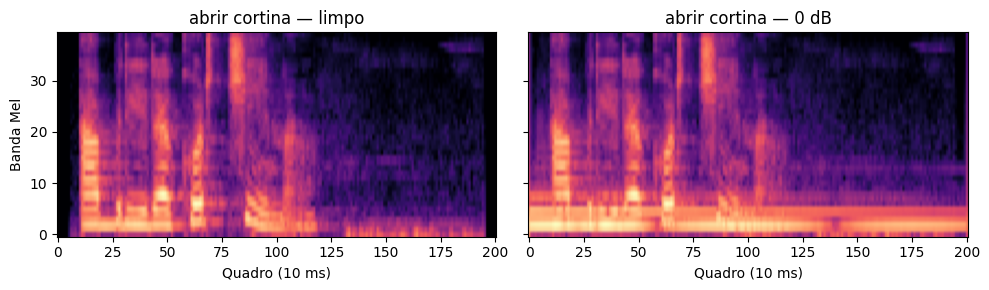

In [7]:
# Exemplo: o mesmo comando limpo e a 0 dB
i = df.index[(df.tipo == "comando") & (df.cond == "limpo")][0]
fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, j, t in [(axs[0], i, "limpo"), (axs[1], i + 3, "0 dB")]:
    ax.imshow(X[j], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"{df.rotulo[j].replace('_', ' ')} — {t}"); ax.set_xlabel("Quadro (10 ms)")
axs[0].set_ylabel("Banda Mel")
plt.tight_layout(); plt.savefig(f"{OUT}/exemplo_logmel.png", dpi=200); plt.show()

## 5. Treinamento

A mesma arquitetura para A e B; só muda o número de saídas (6 ou 7).

- 3 blocos com duas Conv2D 3×3 cada (32, 64 e 128 filtros), BatchNorm, ReLU e MaxPool 2×2
- pooling que resume a frequência mas **mantém 8 trechos de tempo**, preservando a ordem dos sons
  ("ligar" × "desligar" diferem justamente no início da palavra)
- camada densa de 128, Dropout 0,4 e saída com 6 ou 7 classes
- Adam (lr = 1e-3, weight decay 1e-4) com redução cossenoidal da taxa, lotes de 64, até 80 épocas
- parada antecipada pela perda de validação (paciência 20), guardando a melhor época
- SpecAugment opcional (máscaras de tempo e frequência no treino), desligado por padrão

Cada espectrograma é normalizado individualmente (média 0, desvio 1), o que elimina as diferenças de nível
entre o áudio limpo, as versões com ruído e os celulares.
Os dois modelos treinam com as versões limpa e com ruído (20, 10 e 0 dB), como o baseline.

In [8]:
COMANDOS = np.array(sorted(df.loc[df.tipo == "comando", "rotulo"].unique()))
CLASSES = {"CNN A": COMANDOS, "CNN B": np.append(COMANDOS, "fora")}

def mascara(part, tipo=None, cond=None):
    m = df["particao"] == part
    if tipo: m &= df["tipo"] == tipo
    if cond: m &= df["cond"] == cond
    return m.values

tr_cmd = mascara("treino", "comando")
# Normalização por amostra: cada espectrograma com média 0 e desvio 1
media = X.mean(axis=(1, 2), keepdims=True)
desvio = X.std(axis=(1, 2), keepdims=True) + 1e-6
Xn = ((X - media) / desvio)[:, None].astype(np.float32)     # (amostras, 1, 40, 201)

class CNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def bloco(e, s):
            return nn.Sequential(nn.Conv2d(e, s, 3, padding=1), nn.BatchNorm2d(s), nn.ReLU(),
                                 nn.Conv2d(s, s, 3, padding=1), nn.BatchNorm2d(s), nn.ReLU(), nn.MaxPool2d(2))
        self.corpo = nn.Sequential(bloco(1, 32), bloco(32, 64), bloco(64, 128))   # 40×201 → 5×25
        self.cabeca = nn.Sequential(nn.AdaptiveAvgPool2d((1, 8)), nn.Flatten(),     # resume a frequência, mantém o tempo
                                    nn.Dropout(0.4), nn.Linear(128 * 8, 128), nn.ReLU(),
                                    nn.Dropout(0.4), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.cabeca(self.corpo(x))

print("Parâmetros:", sum(p.numel() for p in CNN(7).parameters()))

def dados_treino(modelo, part):
    tipos = ["comando"] if modelo == "CNN A" else ["comando", "negativo"]
    m = mascara(part) & df["tipo"].isin(tipos).values
    idx = {c: i for i, c in enumerate(CLASSES[modelo])}
    return torch.tensor(Xn[m]), torch.tensor(df.loc[m, "rotulo"].map(idx).values)

def spec_aug(xb, g):
    # Máscaras de frequência (até 6 bandas) e de tempo (até 25 quadros), valor 0 (= média após normalizar)
    B, _, F, T = xb.shape
    f0 = torch.randint(0, F - 6, (B, 1), generator=g); fw = torch.randint(0, 7, (B, 1), generator=g)
    t0 = torch.randint(0, T - 25, (B, 1), generator=g); tw = torch.randint(0, 26, (B, 1), generator=g)
    af, at = torch.arange(F)[None], torch.arange(T)[None]
    mf = ((af >= f0) & (af < f0 + fw))[:, None, :, None]
    mt = ((at >= t0) & (at < t0 + tw))[:, None, None, :]
    return xb.masked_fill(mf | mt, 0.0)

def fixar_semente(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False

def perda_media(rede, Xt, yt, criterio):
    rede.eval(); total = 0.0
    with torch.no_grad():
        for i in range(0, len(Xt), 256):
            xb, yb = Xt[i:i + 256].to(DEVICE), yt[i:i + 256].to(DEVICE)
            total += criterio(rede(xb), yb).item() * len(xb)
    return total / len(Xt)

def treinar(modelo, seed):
    fixar_semente(seed)
    Xtr, ytr = dados_treino(modelo, "treino")
    Xva, yva = dados_treino(modelo, "val")
    rede = CNN(len(CLASSES[modelo])).to(DEVICE)
    otim = torch.optim.Adam(rede.parameters(), lr=LR, weight_decay=1e-4)
    agenda = torch.optim.lr_scheduler.CosineAnnealingLR(otim, T_max=EPOCAS)
    criterio = nn.CrossEntropyLoss()
    g = torch.Generator().manual_seed(seed)
    curva, melhor, melhor_perda, sem_melhora = [], None, np.inf, 0
    for epoca in range(EPOCAS):
        rede.train()
        for i in torch.randperm(len(Xtr), generator=g).split(LOTE):
            xb = spec_aug(Xtr[i], g) if USAR_SPECAUG else Xtr[i]
            xb, yb = xb.to(DEVICE), ytr[i].to(DEVICE)
            otim.zero_grad(); criterio(rede(xb), yb).backward(); otim.step()
        p_tr, p_va = perda_media(rede, Xtr, ytr, criterio), perda_media(rede, Xva, yva, criterio)
        curva.append((p_tr, p_va))
        agenda.step()
        if p_va < melhor_perda:                              # parada antecipada: melhor época
            melhor_perda, melhor, sem_melhora = p_va, copy.deepcopy(rede.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= PACIENCIA:
                break
    rede.load_state_dict(melhor)
    return rede, np.array(curva), melhor_perda

def probabilidades(rede, m):
    rede.eval(); saida = []
    with torch.no_grad():
        for i in range(0, m.sum(), 256):
            xb = torch.tensor(Xn[m][i:i + 256]).to(DEVICE)
            saida.append(torch.softmax(rede(xb), dim=1).cpu().numpy())
    return np.concatenate(saida)

Parâmetros: 419431


## 6. Escolha do limiar e avaliação

Para cada áudio, a rede dá uma probabilidade por classe. O comando previsto é o de maior probabilidade
entre os 6 comandos, e a confiança é essa probabilidade.

- **CNN A:** aceita se a confiança ≥ limiar.
- **CNN B:** aceita se a classe mais provável **não** for "fora" **e** a confiança ≥ limiar.

Métricas, iguais às do baseline: macro-F1 dos comandos (rejeição conta como erro), falsa aceitação (FA) dos
negativos e falsa rejeição (FR) dos comandos. O limiar minimiza FA + FR na validação, com as condições juntas.

In [9]:
def decidir(modelo, p):
    pc = p[:, :len(COMANDOS)]                                # probabilidades dos 6 comandos
    conf, pred = pc.max(1), COMANDOS[pc.argmax(1)]
    pode = np.ones(len(p), bool) if modelo == "CNN A" else p.argmax(1) < len(COMANDOS)
    return pred, conf, pode

def avaliar(modelo, p_cmd, y_cmd, p_neg, limiar):
    pred, conf, pode = decidir(modelo, p_cmd)
    aceita = pode & (conf >= limiar)
    f1 = f1_score(y_cmd, np.where(aceita, pred, "rejeitado"), labels=COMANDOS, average="macro", zero_division=0)
    _, conf_n, pode_n = decidir(modelo, p_neg)
    return f1, np.mean(pode_n & (conf_n >= limiar)), np.mean(~aceita)

def escolher_limiar(modelo, rede):
    p_cmd, p_neg = probabilidades(rede, mascara("val", "comando")), probabilidades(rede, mascara("val", "negativo"))
    y_cmd = df.loc[mascara("val", "comando"), "rotulo"].values
    grade = np.linspace(0.2, 0.99, 80)
    custo = [sum(avaliar(modelo, p_cmd, y_cmd, p_neg, t)[1:]) for t in grade]
    return grade[int(np.argmin(custo))]

## 7. Execução

In [10]:
particoes = ["val", "teste"] if RODAR_TESTE else ["val"]
resultados, probs, curvas, redes = [], [], {}, {}

for modelo in CLASSES:
    for seed in SEMENTES:
        t0 = time.time()
        rede, curva, perda_val = treinar(modelo, seed)
        lim = escolher_limiar(modelo, rede)
        tempo = time.time() - t0
        print(f"{modelo} | semente {seed} | {len(curva)} épocas | perda val = {perda_val:.3f} | "
              f"limiar = {lim:.2f} | {tempo:.0f} s")
        curvas[(modelo, seed)], redes[(modelo, seed)] = curva, rede
        for part in particoes:
            for cond in CONDS:
                mc, mn = mascara(part, "comando", cond), mascara(part, "negativo", cond)
                f1, fa, fr = avaliar(modelo, probabilidades(rede, mc), df.loc[mc, "rotulo"].values,
                                     probabilidades(rede, mn), lim)
                resultados.append(dict(modelo=modelo, semente=seed, particao=part, cond=cond, limiar=lim,
                                       macroF1=f1, FA=fa, FR=fr, tempo_treino_s=tempo))
            m = mascara(part)
            tab = df.loc[m, ["arquivo", "locutor", "rotulo", "tipo", "particao", "cond"]].copy()
            p = probabilidades(rede, m)
            tab[[f"p_{c}" for c in CLASSES[modelo]]] = p
            tab["modelo"], tab["semente"], tab["limiar"] = modelo, seed, lim
            probs.append(tab)

res = pd.DataFrame(resultados)
res.to_csv(f"{OUT}/resultados_cnn.csv", index=False)
pd.concat(probs).to_csv(f"{OUT}/probabilidades_cnn.csv", index=False)

for part in particoes:
    print(f"\n{part.upper()}: média ± desvio em {len(SEMENTES)} sementes")
    print(res[res.particao == part].groupby(["modelo", "cond"])[["macroF1", "FA", "FR", "tempo_treino_s"]]
          .agg(["mean", "std"]).reindex(CONDS, level=1).round(3))

CNN A | semente 0 | 34 épocas | perda val = 0.717 | limiar = 0.99 | 72 s
CNN A | semente 1 | 37 épocas | perda val = 0.719 | limiar = 0.93 | 67 s
CNN A | semente 2 | 38 épocas | perda val = 0.796 | limiar = 0.81 | 69 s
CNN B | semente 0 | 45 épocas | perda val = 0.865 | limiar = 0.30 | 165 s
CNN B | semente 1 | 50 épocas | perda val = 0.698 | limiar = 0.20 | 184 s
CNN B | semente 2 | 39 épocas | perda val = 0.818 | limiar = 0.20 | 144 s

VAL: média ± desvio em 3 sementes
             macroF1            FA            FR        tempo_treino_s        
                mean    std   mean    std   mean    std           mean     std
modelo cond                                                                   
CNN A  limpo   0.531  0.159  0.215  0.141  0.535  0.223         69.088   2.339
       20dB    0.534  0.157  0.194  0.179  0.545  0.202         69.088   2.339
       10dB    0.439  0.165  0.125  0.153  0.615  0.245         69.088   2.339
       0dB     0.305  0.172  0.057  0.090  0.764  

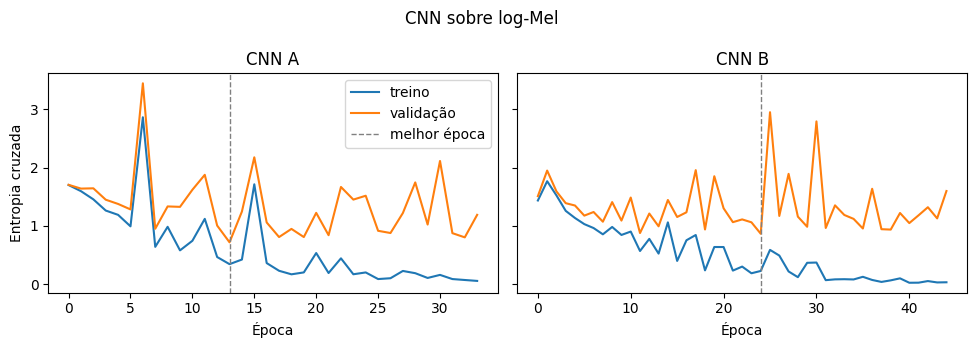

In [11]:
# Curvas de treino e validação (semente 0)
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, modelo in zip(eixos, CLASSES):
    c = curvas[(modelo, SEMENTES[0])]
    ax.plot(c[:, 0], label="treino"); ax.plot(c[:, 1], label="validação")
    ax.axvline(np.argmin(c[:, 1]), color="gray", ls="--", lw=1, label="melhor época")
    ax.set_title(modelo); ax.set_xlabel("Época")
eixos[0].set_ylabel("Entropia cruzada"); eixos[0].legend()
fig.suptitle("CNN sobre log-Mel")
fig.tight_layout(); fig.savefig(f"{OUT}/curvas_cnn.png", dpi=200); plt.show()

In [12]:
# Diagnóstico: acerto sem limiar × rejeição com limiar (validação, todas as condições)
mc = mascara("val", "comando"); y = df.loc[mc, "rotulo"].values
for (modelo, seed), rede in redes.items():
    pred, conf, pode = decidir(modelo, probabilidades(rede, mc))
    lim = res[(res.modelo == modelo) & (res.semente == seed)].limiar.iloc[0]
    print(f"{modelo} s{seed} | acerto sem limiar: {np.mean(pred == y):.2f} | "
          f"rejeitados: {np.mean(~(pode & (conf >= lim))):.2f} | "
          f"confiança média: {conf.mean():.2f} | limiar: {lim:.2f}")

CNN A s0 | acerto sem limiar: 0.70 | rejeitados: 0.78 | confiança média: 0.75 | limiar: 0.99
CNN A s1 | acerto sem limiar: 0.71 | rejeitados: 0.68 | confiança média: 0.74 | limiar: 0.93
CNN A s2 | acerto sem limiar: 0.73 | rejeitados: 0.38 | confiança média: 0.81 | limiar: 0.81
CNN B s0 | acerto sem limiar: 0.66 | rejeitados: 0.13 | confiança média: 0.71 | limiar: 0.30
CNN B s1 | acerto sem limiar: 0.73 | rejeitados: 0.14 | confiança média: 0.73 | limiar: 0.20
CNN B s2 | acerto sem limiar: 0.65 | rejeitados: 0.14 | confiança média: 0.61 | limiar: 0.20


## 8. Comparação com o baseline

Se o `resultados_baseline.csv` do notebook do baseline estiver em `saida/` (ou na pasta do Drive), ele entra
na tabela e nas figuras. Como a divisão e os ruídos são os mesmos, os três modelos são diretamente comparáveis.

Baseline carregado de /content/drive/MyDrive/Projetos/Deteccao_Vozes/saida_baseline/resultados_baseline.csv


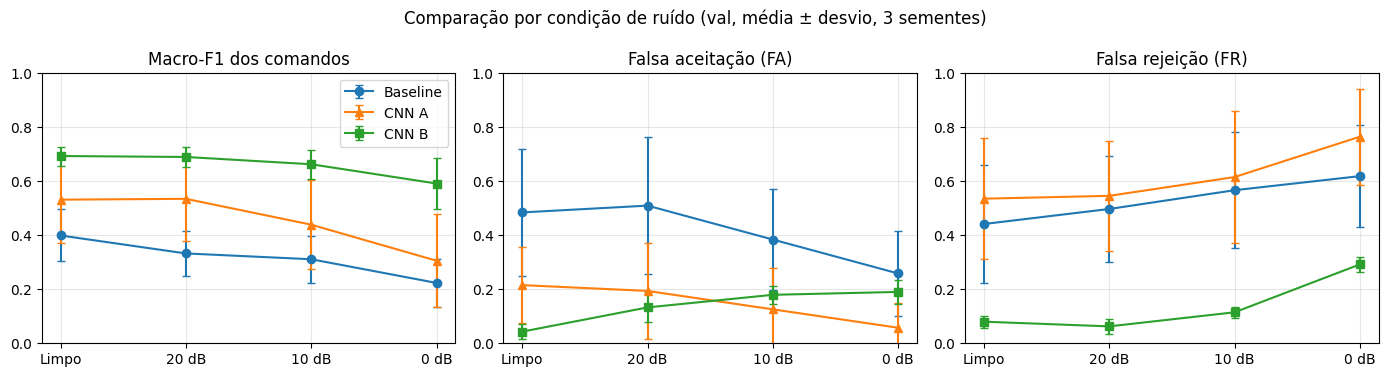

               macroF1            FA            FR       
                  mean    std   mean    std   mean    std
modelo   cond                                            
Baseline limpo   0.399  0.096  0.484  0.236  0.441  0.219
         20dB    0.332  0.085  0.509  0.252  0.497  0.196
         10dB    0.311  0.088  0.384  0.185  0.566  0.214
         0dB     0.223  0.089  0.258  0.156  0.618  0.188
CNN A    limpo   0.531  0.159  0.215  0.141  0.535  0.223
         20dB    0.534  0.157  0.194  0.179  0.545  0.202
         10dB    0.439  0.165  0.125  0.153  0.615  0.245
         0dB     0.305  0.172  0.057  0.090  0.764  0.177
CNN B    limpo   0.692  0.035  0.043  0.028  0.080  0.022
         20dB    0.689  0.038  0.133  0.055  0.062  0.028
         10dB    0.662  0.053  0.179  0.033  0.115  0.021
         0dB     0.591  0.096  0.190  0.043  0.292  0.028


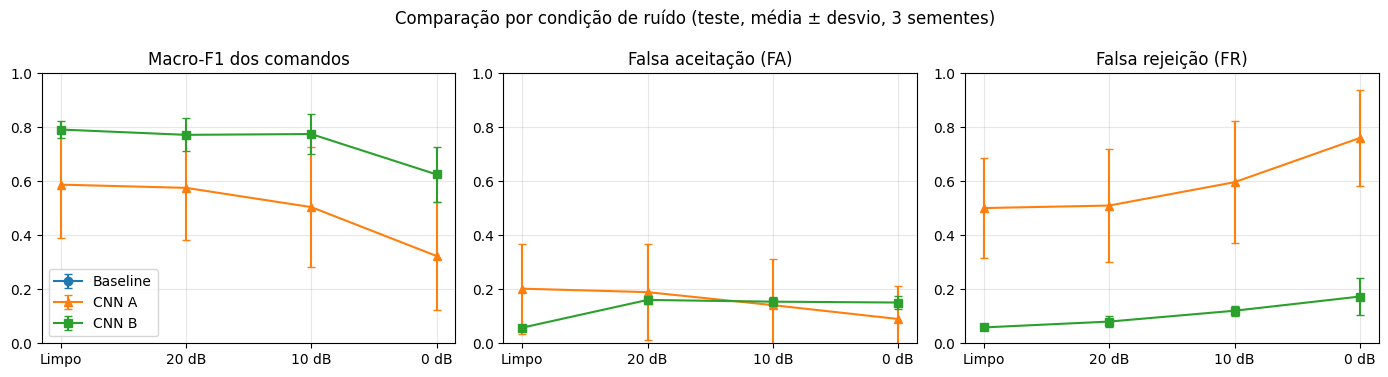

             macroF1            FA            FR       
                mean    std   mean    std   mean    std
modelo cond                                            
CNN A  limpo   0.587  0.196  0.202  0.167  0.500  0.186
       20dB    0.575  0.193  0.189  0.178  0.509  0.210
       10dB    0.504  0.221  0.141  0.169  0.596  0.225
       0dB     0.323  0.201  0.090  0.122  0.759  0.176
CNN B  limpo   0.790  0.033  0.058  0.010  0.059  0.011
       20dB    0.771  0.061  0.160  0.015  0.080  0.019
       10dB    0.774  0.074  0.154  0.017  0.120  0.019
       0dB     0.624  0.103  0.151  0.024  0.173  0.068


In [13]:
tabelas = [res]
for caminho in [f"{OUT}/resultados_baseline.csv",
                "/content/drive/MyDrive/Projetos/Deteccao_Vozes/saida_baseline/resultados_baseline.csv"]:
    if os.path.exists(caminho):
        tabelas.insert(0, pd.read_csv(caminho)); print("Baseline carregado de", caminho); break
else:
    print("resultados_baseline.csv não encontrado: comparação só entre as CNNs.")
todos = pd.concat(tabelas, ignore_index=True)
todos.to_csv(f"{OUT}/resultados_todos.csv", index=False)
MODELOS = list(dict.fromkeys(todos["modelo"]))

def figura_por_ruido(part):
    eixo_x = ["Limpo", "20 dB", "10 dB", "0 dB"]
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    for ax, met, nome in zip(axs, ["macroF1", "FA", "FR"],
                             ["Macro-F1 dos comandos", "Falsa aceitação (FA)", "Falsa rejeição (FR)"]):
        for modelo, mk in zip(MODELOS, "o^s"):
            g = todos[(todos.modelo == modelo) & (todos.particao == part)].groupby("cond")[met]
            mu, sd = g.mean().reindex(CONDS), g.std().reindex(CONDS)
            ax.errorbar(eixo_x, mu, yerr=sd, marker=mk, capsize=3, label=modelo)
        ax.set_title(nome); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    axs[0].legend(); fig.suptitle(f"Comparação por condição de ruído ({part}, média ± desvio, 3 sementes)")
    fig.tight_layout(); fig.savefig(f"{OUT}/comparacao_{part}.png", dpi=200); plt.show()

for part in particoes:
    figura_por_ruido(part)
    print(todos[todos.particao == part].groupby(["modelo", "cond"])[["macroF1", "FA", "FR"]]
          .agg(["mean", "std"]).reindex(CONDS, level=1).round(3))

### Critério de decisão (campo 7 do M1)

A classe negativa traz vantagem prática se a CNN B **reduzir a FA em pelo menos 2 pontos percentuais**
em relação à CNN A **sem perder mais de 2 pontos de macro-F1**. A comparação usa a média das 3 sementes
em cada condição. Primeiro na validação; no teste, só na execução final.

In [14]:
def criterio(part):
    g = todos[todos.particao == part].groupby(["modelo", "cond"])[["macroF1", "FA"]].mean()
    linhas = []
    for cond in CONDS:
        a, b = g.loc[("CNN A", cond)], g.loc[("CNN B", cond)]
        dfa, df1 = (a.FA - b.FA) * 100, (b.macroF1 - a.macroF1) * 100
        linhas.append(dict(cond=cond, reducao_FA_pp=round(dfa, 1), variacao_F1_pp=round(df1, 1),
                           vantagem=("sim" if dfa >= 2 and df1 >= -2 else "não")))
    return pd.DataFrame(linhas)

for part in particoes:
    print(f"\n{part.upper()}"); display(criterio(part))


VAL


,cond,reducao_FA_pp,variacao_F1_pp,vantagem
0,limpo,17.2,16.1,sim
1,20dB,6.1,15.5,sim
2,10dB,-5.4,22.3,não
3,0dB,-13.3,28.6,não



TESTE


,cond,reducao_FA_pp,variacao_F1_pp,vantagem
0,limpo,14.4,20.4,sim
1,20dB,2.9,19.6,sim
2,10dB,-1.3,27.0,não
3,0dB,-6.1,30.1,não


## 9. Análise complementar

**Curva FA × FR:** varia o limiar de 0 a 1 e mostra a troca entre aceitar falas inválidas e rejeitar
comandos válidos (validação, semente 0, todas as condições). O ponto marcado é o limiar escolhido.

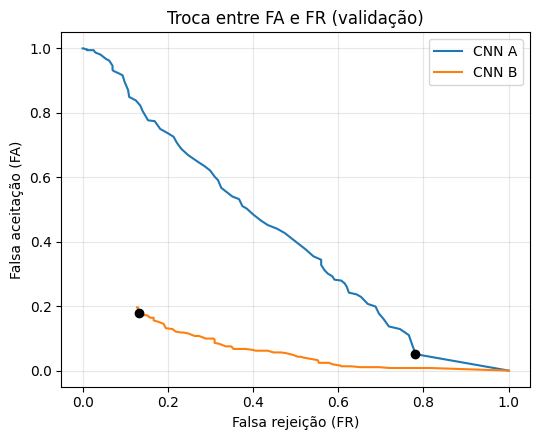

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
mc, mn = mascara("val", "comando"), mascara("val", "negativo")
for modelo in CLASSES:
    rede = redes[(modelo, SEMENTES[0])]
    p_cmd, p_neg = probabilidades(rede, mc), probabilidades(rede, mn)
    y_cmd = df.loc[mc, "rotulo"].values
    pontos = np.array([avaliar(modelo, p_cmd, y_cmd, p_neg, t)[1:] for t in np.linspace(0, 1, 101)])
    ax.plot(pontos[:, 1], pontos[:, 0], label=modelo)
    lim = res[(res.modelo == modelo) & (res.semente == SEMENTES[0])].limiar.iloc[0]
    fa, fr = avaliar(modelo, p_cmd, y_cmd, p_neg, lim)[1:]
    ax.plot(fr, fa, "ko")
ax.set_xlabel("Falsa rejeição (FR)"); ax.set_ylabel("Falsa aceitação (FA)")
ax.set_title("Troca entre FA e FR (validação)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/fa_fr_cnn.png", dpi=200); plt.show()

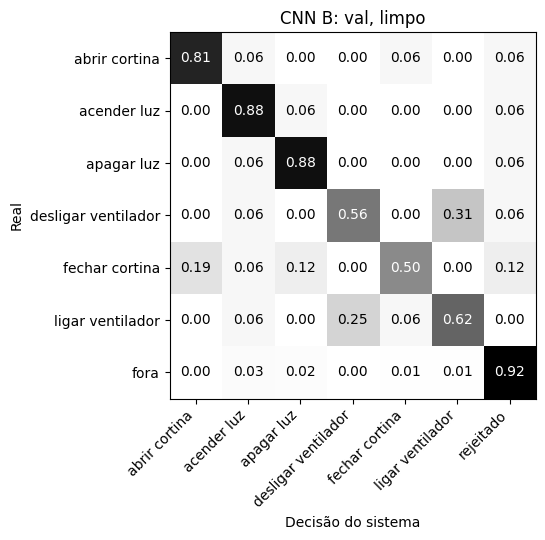

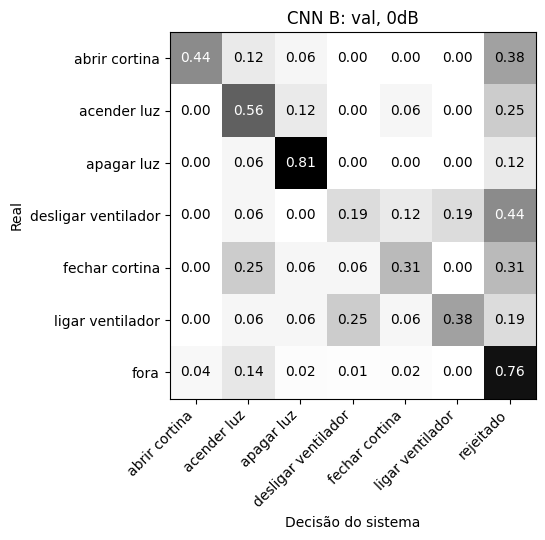

In [16]:
# Matrizes de confusão da CNN B (semente 0), incluindo a rejeição
def matriz(modelo, part, cond):
    rede = redes[(modelo, SEMENTES[0])]
    lim = res[(res.modelo == modelo) & (res.semente == SEMENTES[0])].limiar.iloc[0]
    m = mascara(part, cond=cond)
    pred, conf, pode = decidir(modelo, probabilidades(rede, m))
    prev = np.where(pode & (conf >= lim), pred, "rejeitado")
    real = df.loc[m, "rotulo"].values
    linhas, colunas = list(COMANDOS) + ["fora"], list(COMANDOS) + ["rejeitado"]
    cm = pd.crosstab(pd.Categorical(real, linhas), pd.Categorical(prev, colunas), normalize="index", dropna=False)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm.values, display_labels=None).plot(ax=ax, cmap="Greys", values_format=".2f", colorbar=False)
    ax.set_xticks(range(len(colunas)), [c.replace("_", " ") for c in colunas], rotation=45, ha="right")
    ax.set_yticks(range(len(linhas)), [c.replace("_", " ") for c in linhas])
    ax.set_xlabel("Decisão do sistema"); ax.set_ylabel("Real"); ax.set_title(f"{modelo}: {part}, {cond}")
    plt.tight_layout(); plt.savefig(f"{OUT}/confusao_{modelo.replace(' ', '')}_{part}_{cond}.png", dpi=200); plt.show()

for cond in ["limpo", "0dB"]:
    matriz("CNN B", "val", cond)

## 10. Teste final (rodar uma única vez)

Quando todas as escolhas estiverem fechadas na validação, mude `RODAR_TESTE = True` **aqui e no notebook do
baseline** e execute os dois do início. As tabelas, as figuras `comparacao_teste.png` e o critério de decisão
passam a incluir o teste.

In [17]:
DESTINO = "/content/drive/MyDrive/Projetos/Deteccao_Vozes"
NOME = "saida_cnn"

!cp -r /content/saida/ "$DESTINO/$NOME"
!ls "$DESTINO"

common-voice  dados.zip  figuras_ml  musan  saida_baseline  saida_cnn  saida_ml
